# Does minimizing Walshness help RBMs on the Kitaev model? (proof of concept)

Plans: `plans/01_walshness.md`, `plans/02_ce_basis.md`. Numerics in `walshness.py` and
`ce_basis.py` (self-tests T1-T16 run below).

Four bases $U$, each giving $H_U = UHU^\dagger$ and target $\psi_U = U\psi$:
`naive` ($I$), `local` ($V$), `cliff→local` ($VC$), `local→cliff` ($CV$), and `CE` ($VC$
chosen to minimize the truncated cluster-expansion infidelity, section "CE-optimized basis").
Walshness $W^Z_\alpha[\psi]=\frac1\alpha\log\sum_r p(r)e^{\alpha|r|}$ with $p$ the Walsh
(X-basis) spectrum; optimized at $\alpha=1$.

**Run with at most 30 CPUs**, e.g. `taskset -c 0-29 jupyter nbconvert --execute ...`:
the beam search uses 28 worker processes, the RBM runs 8 processes x 3 CPUs.
Expensive results are cached in `data/` (bases) and `logs/` (RBM runs);
set the flags below to recompute.

In [1]:
import contextlib
import json
import os
import pickle
import sys
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp

import matplotlib.pyplot as plt
import netket as nk
import numpy as np
import pandas as pd

sys.path.append("../Hamiltonians/")
import KitaevHoneycomb as kh
import walshness as wn
import ce_basis as ce

RECOMPUTE_BASES = False
RECOMPUTE_CE = False
RETRAIN = False
os.makedirs("data", exist_ok=True)
os.makedirs("logs", exist_ok=True)
print("NetKet", nk.__version__, "| CPUs available:", len(os.sched_getaffinity(0)))
assert len(os.sched_getaffinity(0)) <= 30, "shared machine: run under taskset with <= 30 CPUs"

NetKet 3.19.2 | CPUs available: 30


## Self-tests (must pass before the experiments)

In [2]:
tests = {**wn.run_tests(verbose=False), **ce.run_tests(verbose=False)}
pd.Series(tests, name="result").to_frame()

,result
T1 bit order,pass
T2 product states,pass
T4 inner solver,pass
T5 GHZ,pass
T7 solver vs FWHT,pass
T9 gates/stim,pass
T10 GHZ+Clifford,pass
T11 H_U,pass
T12 K=2^n exact,pass
T13 rotated product,pass


## Models and ground states

Same parameter sets as in `Kitaev.ipynb`. RBM settings as there (`N_Samples=2**9`,
`alpha=5`, Sgd lr 0.002, SR diag_shift 3e-4, 7000 iterations), one seed for all bases.
NetKet 3.19.2 has `VMC_SR` only in `netket.experimental`.

In [3]:
N_iters = 7000
N_Samples = 2**9
learning_rate = 0.002
diag_shift = 3e-4
RBMAlpha = 5
SEED = 1234
ALPHA = 1.0
CE_K = 18 * RBMAlpha * 18 + 18 + RBMAlpha * 18  # = number of RBM parameters (get_N_params(18, 5))

MODELS = {
    "kitaev_honeycomb": dict(h=(0.0, 0.0, 0.0), J=0.0, K=1.0, Gamma=0.0, GammaPrime=0.0,
                             Lx=3, Ly=3, pbc=True),
    "kitaev_honeycomb_gapped_3": dict(h=(0.05, 0.05, 0.05), J=0.3, K=(0.5, 0.8, 1), Gamma=0.3,
                                      GammaPrime=0.1, Lx=3, Ly=3, pbc=True),
}

M = {}
for name, kw in MODELS.items():
    g, hilbert, H = kh.get_KitaevHoneycomb_Hamiltonian(**kw)
    op_kitaev = H.to_pauli_strings()
    f = f"data/gs_{name}.npz"
    if not os.path.exists(f):
        ev, vecs = nk.exact.lanczos_ed(op_kitaev, k=3, compute_eigenvectors=True)
        np.savez(f, E=ev, vecs=vecs)
    d = np.load(f)
    terms = wn.terms_from_netket(op_kitaev)
    psi = d["vecs"][:, 0] / np.linalg.norm(d["vecs"][:, 0])
    E0 = float(d["E"][0])
    assert abs(wn.pauli_expect(terms, psi) - E0) < 1e-8
    M[name] = dict(terms=terms, psi=psi, E0=E0, E=d["E"], vecs=d["vecs"], n=hilbert.size)
    print(f"{name}: {hilbert.size} sites, {len(terms)} Pauli terms, lowest E = {np.round(d['E'], 6)}")

kitaev_honeycomb: 18 sites, 27 Pauli terms, lowest E = [-14.291503 -14.291503 -14.074638]


kitaev_honeycomb_gapped_3: 18 sites, 297 Pauli terms, lowest E = [-26.53494]


**Caveat (pure Kitaev).** On the 3x3 torus the pure-Kitaev ground state is **3-fold
degenerate** (see the lowest eigenvalues above). Lanczos returns an arbitrary vector of this
manifold; we optimize $U$ for that vector (`vecs[:,0]`). How much the Walshness depends on
this choice is checked on the three Lanczos vectors at the end of the next section. The RBM
energy comparison is unaffected (all bases share the same exact energy); the RBM infidelity is
measured to the whole ground-state manifold. `gapped_3` has a unique ground state, but its gap
to the first excited state is only 0.005.

## Basis optimization

- `local`: inner solver, final mode (Bloch axes + 32 random, continuation 0.25→0.5→1).
- `cliff→local`: beam search over generalized CZ gates $G^{ab}_{ij}$
  ($B=4$, $K=16$, $D_{\max}=n$, patience 2), objective $W_1[C\psi]$.
- `local→cliff`: start from the `local` state $V\psi$, beam search over $\{H_i,S_i,CZ_{ij}\}$
  ($B=4$, all 189 children per parent evaluated exactly by FWHT, $D_{\max}=2n$, patience 2),
  objective fixed-basis $W^Z_1[CV\psi]$. The optional alternating refinement (plan §4.2.4) is
  not done.

In [4]:
def optimize_bases(psi, pool, seed=SEED):
    rng = np.random.default_rng(seed)
    n = wn.nqubits(psi)
    out = {}
    loc = wn.final_mode(psi, ALPHA, rng, pool=pool)
    loc2 = wn.final_mode(psi, 2.0, rng, extra=[loc["axes"]], pool=pool)
    out["local"] = dict(word=[], axes=loc["axes"], W=loc["W"], W2_reopt=loc2["W"],
                        W_restarts=loc["W_all"])
    print("cliff→local beam search", flush=True)
    cl = wn.beam_search(psi, wn.G_gates(n), "intrinsic", ALPHA, B=4, K=16, D_max=n, pool=pool,
                        seed=seed, init_axes=loc["axes"])
    cl2 = wn.final_mode(cl["phi"], 2.0, rng, extra=[cl["axes"]], pool=pool)
    out["cliff→local"] = dict(word=cl["word"], axes=cl["axes"], W=cl["J"], W2_reopt=cl2["W"],
                              history=cl["history"])
    print("local→cliff beam search", flush=True)
    phi0 = wn.apply_local(psi, wn.axes_to_unitaries(loc["axes"]))
    lc = wn.beam_search(phi0, wn.HSCZ_gates(n), "Z", ALPHA, B=4, K=None, D_max=2 * n, pool=pool,
                        seed=seed)
    out["local→cliff"] = dict(word=lc["word"], axes=loc["axes"], W=lc["J"], W2_reopt=np.nan,
                              history=lc["history"])
    return out


for name, m in M.items():
    f = f"data/bases_{name}.pkl"
    if RECOMPUTE_BASES or not os.path.exists(f):
        print(f"=== {name}")
        with wn.make_pool(28) as pool:
            res = optimize_bases(m["psi"], pool)
        with open(f, "wb") as fh:
            pickle.dump(res, fh)
    with open(f, "rb") as fh:
        m["opt"] = pickle.load(fh)

## CE-optimized basis

Plan `02_ce_basis.md`. Objective: the truncated cluster-expansion infidelity
$I_{CE}(\phi;K)=1-|\langle\hat\phi|\hat\phi_K\rangle|^2$, where $\phi_K=\exp$ of the
$K$ largest Walsh coefficients of $\ell=\log\max(|\phi|,10^{-12})+i\arg\phi$ (principal
branch, gauge $\phi_{\arg\max|\phi|}=1$), $K$ = number of RBM parameters = 1728.
Basis $U=VC$: beam search over $G^{ab}_{ij}$ words $C$ ($B=4$, $D_{\max}=n$, patience 2),
objective $\min_V I_{CE}[VC\psi]$ with a general SU(2) per site (L-BFGS on Euler angles).
Children are screened by a forward pass with the parent $V$ (the Walshness LB is no bound
for $I_{CE}$), best 16 per parent are solved (inits: parent $V$, identity, 1 random; 150
iterations). Every new best is re-solved in final mode (identity, warm start, 32 random;
500 iterations). Extra candidate: final-mode CE-local solve on $C_W\psi$ with $C_W$ the
Walshness `cliff→local` word. `CE` = the better of the two.

$I_{CE}$ is non-smooth (top-K set jumps, phases cross the branch cut): restarts are the only
mitigation, and their spread is printed below.

In [5]:
def optimize_ce(m, pool, seed=SEED):
    rng = np.random.default_rng(seed)
    psi, n, opt = m["psi"], m["n"], m["opt"]
    beam = wn.beam_search(psi, wn.G_gates(n), "CE", B=4, K=16, D_max=n, patience=2, pool=pool,
                          seed=seed, ce_K=CE_K,
                          init_Vs=[wn.axes_to_unitaries(opt["local"]["axes"])])
    cw = opt["cliff→local"]
    r = ce.ce_final(wn.apply_word(psi, cw["word"]), CE_K, rng,
                    extra=[wn.axes_to_unitaries(cw["axes"])], pool=pool)
    cands = {"beam": dict(word=beam["word"], Vs=beam["Vs"], I=beam["J"],
                          I_restarts=beam["I_restarts"], history=beam["history"]),
             "walsh word": dict(word=cw["word"], Vs=r["Vs"], I=r["I"], I_restarts=r["I_all"])}
    best = min(cands, key=lambda k: cands[k]["I"])
    return dict(cands[best], source=best, candidates=cands)


for name, m in M.items():
    f = f"data/bases_ce_{name}.pkl"
    if RECOMPUTE_CE or not os.path.exists(f):
        # progress goes to a log file (nbconvert shows cell output only at the end)
        with open(f"logs/ce_search_{name}.log", "w") as log, contextlib.redirect_stdout(log), \
                wn.make_pool(28) as pool:
            res = optimize_ce(m, pool)
        with open(f, "wb") as fh:
            pickle.dump(res, fh)
    with open(f, "rb") as fh:
        m["opt"]["CE"] = pickle.load(fh)

In [6]:
for name, m in M.items():
    o = m["opt"]["CE"]
    print(f"=== {name}: CE basis from '{o['source']}', I_CE({CE_K}) = {o['I']:.4f}")
    for k, c in o["candidates"].items():
        q = np.quantile(c["I_restarts"], [0, 0.5, 1])
        print(f"  {k:10s}: I_CE = {c['I']:.4f}, {len(c['word'])} gates: {wn.word_str(c['word'])}")
        print(f"  {'':10s}  final-mode restarts ({len(c['I_restarts'])}): "
              f"min {q[0]:.4f}, median {q[1]:.4f}, max {q[2]:.4f}")
    print("  beam history (depth, best I_CE, wall s):",
          [(h["depth"], round(h["J"], 4), round(h["t"])) for h in o["candidates"]["beam"]["history"]])

=== kitaev_honeycomb: CE basis from 'beam', I_CE(1728) = 0.1153
  beam      : I_CE = 0.1153, 12 gates: CY[0, 11] CY[2, 6] YCZ[16, 17] CY[3, 13] YCZ[10, 13] CY[6, 7] CY[1, 15] YCZ[12, 16] YCZ[8, 12] YCZ[12, 16] CY[3, 5] YCZ[12, 16]
              final-mode restarts (34): min 0.1153, median 0.7202, max 0.9983
  walsh word: I_CE = 0.2244, 9 gates: XCZ[4, 17] YCZ[7, 8] CY[10, 11] XCZ[2, 3] CX[1, 6] YCX[0, 5] XCZ[12, 13] YCZ[15, 16] XCY[9, 14]
              final-mode restarts (34): min 0.2244, median 0.8292, max 0.9785
  beam history (depth, best I_CE, wall s): [(0, np.float64(0.3914), 0), (1, np.float64(0.1693), 133), (2, np.float64(0.142), 381), (3, np.float64(0.1346), 597), (4, np.float64(0.1296), 808), (5, 0.1251, 1036), (6, 0.1218, 1250), (7, np.float64(0.12), 1453), (8, np.float64(0.1189), 1658), (9, 0.1167, 1855), (10, np.float64(0.1163), 2057), (11, np.float64(0.1163), 2226), (12, 0.1153, 2451), (13, 0.1153, 2615), (14, 0.1153, 2786)]
=== kitaev_honeycomb_gapped_3: CE basis from 'b

## Transformed states and Hamiltonians

Order matters: `cliff→local` is $U=VC$ (gates first), `local→cliff` is $U=CV$ (rotation first).
The Clifford part is conjugated with `stim` (no term growth possible, equal strings merge);
the local part expands $\sigma^a\mapsto\sum_b R_{ba}\sigma^b$ (up to $3^w$ terms per weight-$w$
string, merged, $|w|<10^{-12}$ dropped). $V$ is the canonical minimal rotation of plan §3.
Checks: $\langle\psi_U|H_U|\psi_U\rangle=E_0$ and the solver value equals the FWHT value.

In [7]:
BASES = ["naive", "local", "cliff→local", "local→cliff", "CE"]


def transform(m, basis):
    psi, terms = m["psi"], m["terms"]
    if basis == "naive":
        return psi, terms, len(terms), None
    o = m["opt"][basis]
    Vs = o["Vs"] if "Vs" in o else wn.axes_to_unitaries(o["axes"])
    if basis in ("local", "cliff→local", "CE"):  # U = V C
        tC, _ = wn.clifford_conjugate(terms, o["word"]) if o["word"] else (terms, None)
        HU, nb = wn.local_conjugate(tC, Vs)
        psiU = wn.apply_local(wn.apply_word(psi, o["word"]), Vs)
    else:  # U = C V
        tV, nb = wn.local_conjugate(terms, Vs)
        HU, _ = wn.clifford_conjugate(tV, o["word"]) if o["word"] else (tV, None)
        psiU = wn.apply_word(wn.apply_local(psi, Vs), o["word"])
    return psiU, HU, nb, o


rows = []
for name, m in M.items():
    m["U"] = {}
    for basis in BASES:
        psiU, HU, nb, o = transform(m, basis)
        assert abs(wn.pauli_expect(HU, psiU) - m["E0"]) < 1e-7, (name, basis)
        # the other degenerate vectors, transformed with the same U (RBM infidelity target)
        if basis == "naive":
            targets = [m["vecs"][:, k] for k in range(m["vecs"].shape[1]) if m["E"][k] - m["E0"] < 1e-6]
        else:
            targets = [transform(dict(m, psi=t), basis)[0] for t in M[name]["U"]["naive"]["targets"]]
        st = wn.term_stats(HU, nb)
        row = dict(model=name, basis=basis, W1=wn.walshness_Z(psiU, 1.0),
                   W2=wn.walshness_Z(psiU, 2.0),
                   W2_reopt=np.nan if o is None else o.get("W2_reopt", np.nan),
                   LB=wn.lower_bound(psiU), **{f"I_CE_{CE_K}": ce.ce_infidelity(psiU, CE_K)},
                   word_len=0 if o is None else len(o["word"]),
                   snap_err=np.nan if o is None or "axes" not in o else wn.snapping_error(o["axes"]),
                   terms_before_merge=st["n_before"], terms=st["n_terms"],
                   terms_gt_1e8=st["n_gt_1e8"], terms_gt_1e4=st["n_gt_1e4"],
                   max_weight=st["max_weight"])
        m["U"][basis] = dict(psi=psiU, H=HU, targets=targets, row=row)
        rows.append(row)
        if o is not None and "W" in o:  # optimizer value vs FWHT value of psi_U (plan §3 final check)
            assert abs(o["W"] - row["W1"]) < 1e-8, (name, basis, o["W"], row["W1"])
        if basis == "CE":
            assert abs(o["I"] - row[f"I_CE_{CE_K}"]) < 1e-6, (name, o["I"], row[f"I_CE_{CE_K}"])
table = pd.DataFrame(rows).set_index(["model", "basis"])
pd.set_option("display.precision", 4)
table

W1       W2  W2_reopt      LB  \
model                     basis                                             
kitaev_honeycomb          naive        10.1611  11.4810       NaN  9.0000   
                          local        10.0386  11.1169   11.0446  9.0000   
                          cliff→local   8.1814   9.5251    9.5251  6.5584   
                          local→cliff   9.5889  11.3388       NaN  7.1821   
                          CE           11.5424  13.0868       NaN  8.7295   
kitaev_honeycomb_gapped_3 naive         9.8204  10.7371       NaN  8.9803   
                          local         9.0093   9.0439    9.0439  8.9803   
                          cliff→local   6.0132   8.7776    8.5975  4.0480   
                          local→cliff   9.0093   9.0439       NaN  8.9803   
                          CE            9.3240   9.8035       NaN  8.5719   

                                       I_CE_1728  word_len    snap_err  \
model                     basis                                          
kitaev_honeycomb          naive           0.7673         0         NaN   
                          local           0.9559         0  2.6212e-01   
                          cliff→local     0.3083         9  9.8810e-15   
                          local→cliff     0.9720        20  2.6212e-01   
                          CE              0.1153        12         NaN   
kitaev_honeycomb_gapped_3 naive           0.9486         0         NaN   
                          local           0.8558         0  3.5115e-01   
                          cliff→local     0.8069         9  1.8352e-01   
                          local→cliff     0.8558         0  3.5115e-01   
                          CE              0.0063         7         NaN   

                                       terms_before_merge  terms  \
model                     basis                                    
kitaev_honeycomb          naive                        27     27   
                          local                       243    243   
                          cliff→local                 124     87   
                          local→cliff                 243    243   
                          CE                         3711   2739   
kitaev_honeycomb_gapped_3 naive                       297    297   
                          local                      2349    297   
                          cliff→local                8829   2691   
                          local→cliff                2349    297   
                          CE                         3885    630   

                                       terms_gt_1e8  terms_gt_1e4  max_weight  
model                     basis                                                
kitaev_honeycomb          naive                  27            27           2  
                          local                 243           233           2  
                          cliff→local            79            27           4  
                          local→cliff           243           233           7  
                          CE                   1581           399           6  
kitaev_honeycomb_gapped_3 naive                 297           297           2  
                          local                 297           297           2  
                          cliff→local          2151           969           4  
                          local→cliff           297           297           2  
                          CE                    630           628           4

Columns: `W1`, `W2` = fixed-basis $W^Z_{1,2}[\psi_U]$ of the actual RBM target;
`I_CE_1728` = truncated-CE infidelity of $\psi_U$ at $K=1728$; `snap_err` is NaN for `CE`
(general SU(2) $V$, no axes);
`W2_reopt` = intrinsic $W_2$ with $V$ re-optimized at $\alpha=2$ (same Clifford);
`LB` = rigorous lower bound (local-invariant); `snap_err` = $\max_j(1-\max_a|n_{j,a}|)$,
0 iff every optimized axis is a $\pm$Pauli axis; `terms_before_merge` counts the expanded
strings before merging. The RBM is trained on the exact (unsnapped, unthresholded) $H_U$.

**Snapping check.** Where the optimized axes are within $10^{-6}$ of $\pm$Pauli axes, $V$ is
(up to solver precision) a local Clifford; snapping them exactly gives the Clifford-only term
count and the Walshness cost of snapping:

In [8]:
for name, m in M.items():
    for basis in ("local", "cliff→local"):  # U = V C (local→cliff reuses the `local` axes)
        o = m["opt"][basis]
        if wn.snapping_error(o["axes"]) > 1e-6:
            continue
        snapped = np.round(o["axes"])
        Vs = wn.axes_to_unitaries(snapped)
        HU = wn.local_conjugate(wn.clifford_conjugate(m["terms"], o["word"])[0] if o["word"]
                                else m["terms"], Vs)[0]
        psiU = wn.apply_local(wn.apply_word(m["psi"], o["word"]), Vs)
        print(f"{name} {basis}: snapped W1 = {wn.walshness_Z(psiU, 1.0):.8f} "
              f"(unsnapped {o['W']:.8f}), terms {len(m['terms'])} -> {len(HU)}, "
              f"max weight {wn.term_stats(HU)['max_weight']}")

kitaev_honeycomb cliff→local: snapped W1 = 8.18138620 (unsnapped 8.18138620), terms 27 -> 27, max weight 4


In [9]:
for name, m in M.items():
    for basis in ("cliff→local", "local→cliff"):
        o = m["opt"][basis]
        print(f"{name} {basis}: {len(o['word'])} gates: {wn.word_str(o['word'])}")
        print("   depth, best J, wall time:",
              [(h["depth"], round(h["J"], 4), round(h["t"])) for h in o["history"]])

kitaev_honeycomb cliff→local: 9 gates: XCZ[4, 17] YCZ[7, 8] CY[10, 11] XCZ[2, 3] CX[1, 6] YCX[0, 5] XCZ[12, 13] YCZ[15, 16] XCY[9, 14]
   depth, best J, wall time: [(0, np.float64(10.0386), 0), (1, np.float64(9.8765), 54), (2, np.float64(9.6832), 89), (3, np.float64(9.4903), 133), (4, np.float64(9.3148), 173), (5, np.float64(9.0907), 199), (6, np.float64(8.9032), 220), (7, np.float64(8.6472), 234), (8, np.float64(8.4554), 247), (9, np.float64(8.1814), 271), (10, np.float64(8.1814), 281), (11, np.float64(8.1814), 290)]
kitaev_honeycomb local→cliff: 20 gates: CZ[10, 11] CZ[0, 1] CZ[12, 13] CZ[7, 8] CZ[9, 14] S[9] CZ[4, 17] H[17] CZ[2, 15] CZ[16, 17] H[3] CZ[3, 8] H[8] CZ[8, 12] CZ[5, 16] S[5] H[6] CZ[6, 12] S[12] S[5]
   depth, best J, wall time: [(0, np.float64(10.0386), 0), (1, np.float64(9.9882), 5), (2, np.float64(9.9609), 16), (3, np.float64(9.9506), 27), (4, np.float64(9.9506), 37), (5, np.float64(9.937), 46), (6, np.float64(9.8513), 54), (7, np.float64(9.8469), 63), (8, np.float64

### Ambiguity of the degenerate pure-Kitaev ground state

Naive and local Walshness for each of the three Lanczos vectors of the degenerate manifold
(local: final mode with 8 random restarts).

In [10]:
m = M["kitaev_honeycomb"]
rng = np.random.default_rng(SEED)
amb = []
with wn.make_pool(28) as pool:
    for k, t in enumerate(m["U"]["naive"]["targets"]):
        t = t / np.linalg.norm(t)
        amb.append(dict(vector=k, W1_naive=wn.walshness_Z(t, 1.0),
                        W1_local=wn.final_mode(t, 1.0, rng, n_random=8, pool=pool)["W"],
                        LB=wn.lower_bound(t)))
pd.DataFrame(amb).set_index("vector")

,W1_naive,W1_local,LB
vector,,,
0,10.1611,10.0386,9.0
1,10.2028,10.0390,9.0


### Hamming-weight histograms of the Walsh spectrum

$P(|r|_1=k)$ of $\psi_U$ for each basis. Lower $k$ = more weight near $|+\rangle^{\otimes n}$.

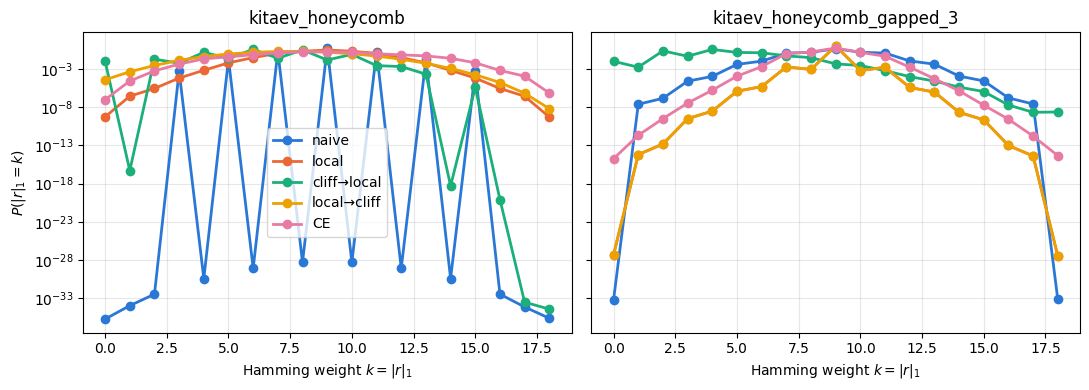

In [11]:
COLORS = dict(zip(BASES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
fig, axes = plt.subplots(1, len(M), figsize=(11, 4), sharey=True)
for ax, (name, m) in zip(axes, M.items()):
    for basis in BASES:
        hist = wn.hamming_histogram(m["U"][basis]["psi"])
        ax.semilogy(np.arange(len(hist)), hist, "o-", lw=2, ms=6, color=COLORS[basis], label=basis)
    ax.set_title(name)
    ax.set_xlabel("Hamming weight $k=|r|_1$")
    ax.grid(True, alpha=0.3, which="both")
axes[0].set_ylabel("$P(|r|_1=k)$")
axes[0].legend()
plt.tight_layout()
plt.show()

### Truncated-CE infidelity vs. number of kept coefficients

$I_{CE}(K)$ of $\psi_U$, $K=2^4\ldots2^{18}$; dashed line at $K=1728$ (number of RBM
parameters). $I_{CE}$ need not be monotone in $K$ (truncating the phase part of a wrapped
principal log can make things worse).

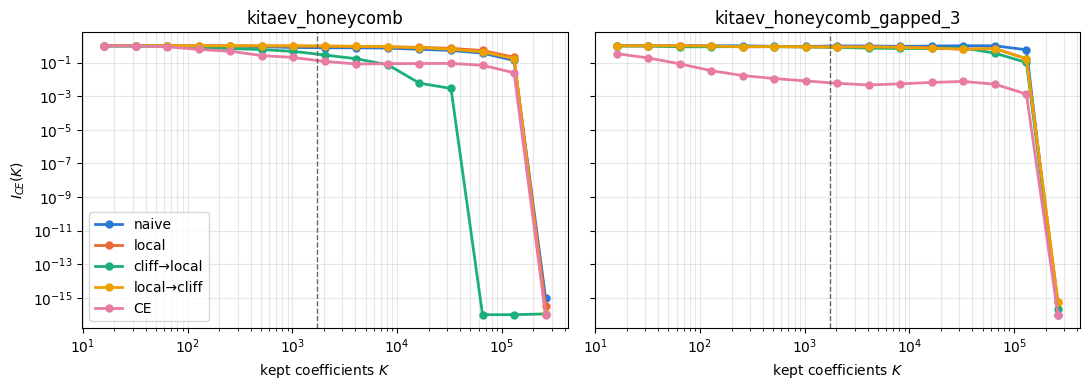

In [12]:
Ks = 2 ** np.arange(4, 19)
fig, axes = plt.subplots(1, len(M), figsize=(11, 4), sharey=True)
for ax, (name, m) in zip(axes, M.items()):
    for basis in BASES:
        I = [ce.ce_infidelity(m["U"][basis]["psi"], K) for K in Ks]
        ax.loglog(Ks, np.maximum(I, 1e-16), "o-", lw=2, ms=5, color=COLORS[basis], label=basis)
    ax.axvline(CE_K, color="0.4", ls="--", lw=1)
    ax.set_title(name)
    ax.set_xlabel("kept coefficients $K$")
    ax.grid(True, alpha=0.3, which="both")
axes[0].set_ylabel("$I_{CE}(K)$")
axes[0].legend()
plt.tight_layout()
plt.savefig("figs/walshness_kitaev_ce_vs_K.png", dpi=150, bbox_inches="tight")
plt.show()

## RBM training on $H_U$

Ten independent runs (2 models x 5 bases), run in parallel, each pinned to 3 CPUs; only
runs without a log are trained.
Logs go to `logs/{model}_walsh_{basis}.json` with metadata (basis, Walshness, term counts, ...).

In [13]:
def logfile(name, basis):
    return f"logs/{name}_walsh_{basis.replace('→', '-to-')}.json"


os.environ.pop("XLA_FLAGS", None)  # set by wn.make_pool (1 thread per worker); RBM runs use 3
jobs = []
cpus = sorted(os.sched_getaffinity(0))
for name, m in M.items():
    for basis in BASES:
        f = logfile(name, basis)
        if RETRAIN or not os.path.exists(f):
            r = m["U"][basis]["row"]
            meta = dict(modelname=name, basis=basis, alpha=ALPHA, exact_energy=m["E0"],
                        **{k: (v if isinstance(v, (int, str)) else float(v)) for k, v in r.items()
                           if k not in ("model", "basis")}, **MODELS[name])
            jobs.append((m["U"][basis]["H"], f, m["U"][basis]["targets"], meta))
print(f"{len(jobs)} runs to train")
if jobs:
    k = 3
    assert len(jobs) * k <= len(cpus), "not enough CPUs for one run per 3 CPUs"
    with ProcessPoolExecutor(len(jobs), mp_context=mp.get_context("spawn"),
                             max_tasks_per_child=1) as ex:
        futs = [ex.submit(wn.train_rbm, H_U, f, targets, cpus=cpus[k * i:k * (i + 1)], seed=SEED,
                          n_iter=N_iters, n_samples=N_Samples, lr=learning_rate,
                          diag_shift=diag_shift, rbm_alpha=RBMAlpha, metadata=meta)
                for i, (H_U, f, targets, meta) in enumerate(jobs)]
        for fu in futs:
            print("done:", fu.result(), flush=True)

2 runs to train


Automatic SR implementation choice:  NTK


done: logs/kitaev_honeycomb_walsh_CE.json


done: logs/kitaev_honeycomb_gapped_3_walsh_CE.json


Automatic SR implementation choice:  NTK


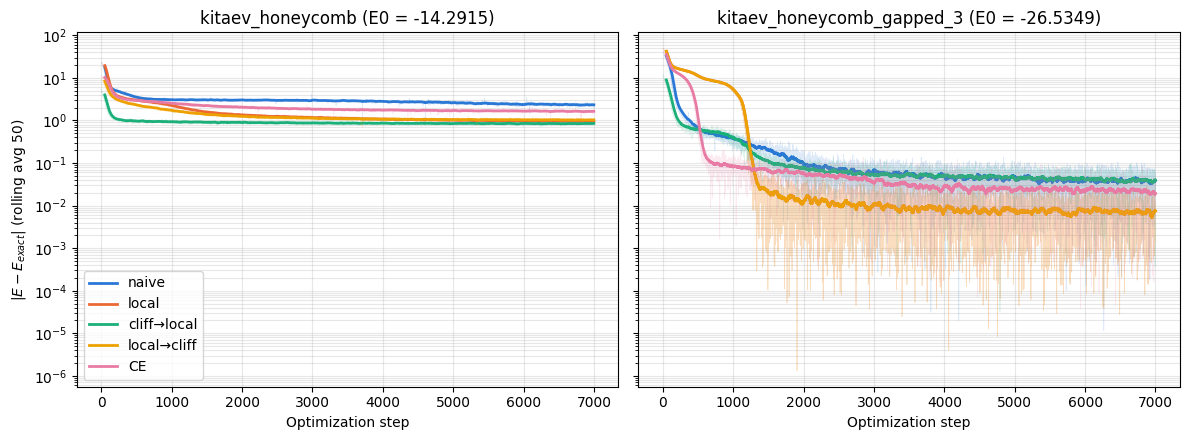

In [14]:
def load_log(f):
    with open(f) as fh:
        d = json.load(fh)
    E = d["Energy"]["Mean"]
    E = np.asarray(E["real"]) if isinstance(E, dict) else np.real(np.asarray(E))
    return np.asarray(d["Energy"]["iters"]), E, d


def rolling_average(data, window_size):
    return np.convolve(data, np.ones(window_size) / window_size, mode="valid")


window = 50
fig, axes = plt.subplots(1, len(M), figsize=(12, 4.5), sharey=True)
final = []
for ax, (name, m) in zip(axes, M.items()):
    for basis in BASES:
        it, E, d = load_log(logfile(name, basis))
        err = np.abs(E - m["E0"])
        ax.semilogy(it, err, color=COLORS[basis], alpha=0.15, lw=0.5)
        ax.semilogy(it[window - 1:], rolling_average(err, window), color=COLORS[basis], lw=2,
                    label=basis)
        tail = E[-500:] - m["E0"]
        final.append(dict(model=name, basis=basis, E_err_last500=tail.mean(),
                          E_err_std_last500=tail.std(), rel_err=tail.mean() / abs(m["E0"]),
                          infidelity=d["final_infidelity"], wall_min=d["wall_time"] / 60))
    ax.set_title(f"{name} (E0 = {m['E0']:.4f})")
    ax.set_xlabel("Optimization step")
    ax.grid(True, alpha=0.3, which="both")
axes[0].set_ylabel(f"$|E-E_{{exact}}|$ (rolling avg {window})")
axes[0].legend()
plt.tight_layout()
plt.savefig("figs/walshness_kitaev_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary table

`E_err_last500` = mean of $E-E_0$ over the last 500 iterations (± std over those iterations;
this is MC + optimization noise of a **single seed**, not a seed-to-seed error bar).
`infidelity` = $1-\sum_k|\langle\psi_U^{(k)}|\phi\rangle|^2$ over the (degenerate) ground
states, computed from `to_array()`.

In [15]:
summary = table.join(pd.DataFrame(final).set_index(["model", "basis"]))
summary[["W1", "W2", "W2_reopt", "LB", f"I_CE_{CE_K}", "word_len", "terms", "max_weight", "snap_err",
         "E_err_last500", "E_err_std_last500", "rel_err", "infidelity"]]

W1       W2  W2_reopt      LB  \
model                     basis                                             
kitaev_honeycomb          naive        10.1611  11.4810       NaN  9.0000   
                          local        10.0386  11.1169   11.0446  9.0000   
                          cliff→local   8.1814   9.5251    9.5251  6.5584   
                          local→cliff   9.5889  11.3388       NaN  7.1821   
                          CE           11.5424  13.0868       NaN  8.7295   
kitaev_honeycomb_gapped_3 naive         9.8204  10.7371       NaN  8.9803   
                          local         9.0093   9.0439    9.0439  8.9803   
                          cliff→local   6.0132   8.7776    8.5975  4.0480   
                          local→cliff   9.0093   9.0439       NaN  8.9803   
                          CE            9.3240   9.8035       NaN  8.5719   

                                       I_CE_1728  word_len  terms  max_weight  \
model                     basis                                                 
kitaev_honeycomb          naive           0.7673         0     27           2   
                          local           0.9559         0    243           2   
                          cliff→local     0.3083         9     87           4   
                          local→cliff     0.9720        20    243           7   
                          CE              0.1153        12   2739           6   
kitaev_honeycomb_gapped_3 naive           0.9486         0    297           2   
                          local           0.8558         0    297           2   
                          cliff→local     0.8069         9   2691           4   
                          local→cliff     0.8558         0    297           2   
                          CE              0.0063         7    630           4   

                                         snap_err  E_err_last500  \
model                     basis                                    
kitaev_honeycomb          naive               NaN         2.3385   
                          local        2.6212e-01         0.9649   
                          cliff→local  9.8810e-15         0.8452   
                          local→cliff  2.6212e-01         1.0292   
                          CE                  NaN         1.6385   
kitaev_honeycomb_gapped_3 naive               NaN         0.0358   
                          local        3.5115e-01         0.0052   
                          cliff→local  1.8352e-01         0.0385   
                          local→cliff  3.5115e-01         0.0052   
                          CE                  NaN         0.0210   

                                       E_err_std_last500  rel_err  infidelity  
model                     basis                                                
kitaev_honeycomb          naive                   0.1126   0.1636      1.0000  
                          local                   0.0415   0.0675      0.9940  
                          cliff→local             0.0365   0.0591      0.9383  
                          local→cliff             0.0394   0.0720      0.9957  
                          CE                      0.0728   0.1146      0.9990  
kitaev_honeycomb_gapped_3 naive                   0.0255   0.0014      0.9876  
                          local                   0.0069   0.0002      0.4999  
                          cliff→local             0.0160   0.0015      0.5001  
                          local→cliff             0.0069   0.0002      0.4999  
                          CE                      0.0144   0.0008      0.5009